# MovieLens Latest Small: Exploratory Data Analysis

This notebook provides reproducible exploratory analysis for a personalized Top-K movie recommendation research project. It reads the raw MovieLens files without modifying them and does not perform preprocessing, splitting, feature engineering, or modelling.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

src_path = str(PROJECT_ROOT / "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

from movie_recommender.data_loader import (
    load_links,
    load_movies,
    load_ratings,
    load_tags,
)

FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
plt.style.use("default")
pd.set_option("display.max_rows", 30)

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\wublub902\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


In [2]:
ratings = load_ratings()
movies = load_movies()
tags = load_tags()
links = load_links()

ratings.shape, movies.shape, tags.shape, links.shape

((100836, 4), (9742, 3), (3683, 4), (9742, 3))

## 1. Dataset Overview

Dataset scale determines computational requirements and the amount of evidence available for personalization. User and movie activity averages indicate how much signal a recommender can learn, while the time span indicates whether preference drift may matter.

In [3]:
rating_datetimes = pd.to_datetime(ratings["timestamp"], unit="s")
ratings_per_user = ratings.groupby("userId").size()
ratings_per_movie = ratings.groupby("movieId").size()

overview = pd.Series(
    {
        "Users": ratings["userId"].nunique(),
        "Movies in catalog": movies["movieId"].nunique(),
        "Movies with ratings": ratings["movieId"].nunique(),
        "Ratings": len(ratings),
        "Tags": len(tags),
        "First rating": rating_datetimes.min(),
        "Last rating": rating_datetimes.max(),
        "Average ratings per user": ratings_per_user.mean(),
        "Average ratings per rated movie": ratings_per_movie.mean(),
    },
    name="Value",
)
overview

Users                                              610
Movies in catalog                                 9742
Movies with ratings                               9724
Ratings                                         100836
Tags                                              3683
First rating                       1996-03-29 18:36:55
Last rating                        2018-09-24 14:27:30
Average ratings per user                    165.304918
Average ratings per rated movie              10.369807
Name: Value, dtype: object

The dataset contains 610 users, 9,742 catalog movies, 100,836 ratings, and 3,683 tags from March 1996 through September 2018. Users provide about 165 ratings on average, but rated movies receive only about 10 ratings on average. These averages hide substantial activity imbalance examined below.

## 2. Data Quality

The following checks cover missing values, exact duplicate rows, duplicate user–movie rating interactions, and inferred data types.

In [4]:
datasets = {"ratings": ratings, "movies": movies, "tags": tags, "links": links}
quality_summary = pd.DataFrame(
    {
        name: {
            "rows": len(frame),
            "missing_values": int(frame.isna().sum().sum()),
            "duplicate_rows": int(frame.duplicated().sum()),
        }
        for name, frame in datasets.items()
    }
).T
quality_summary

,rows,missing_values,duplicate_rows
ratings,100836,0,0
movies,9742,0,0
tags,3683,0,0
links,9742,8,0


In [5]:
missing_by_column = pd.concat(
    {name: frame.isna().sum() for name, frame in datasets.items()},
    names=["dataset", "column"],
).rename("missing_values")
missing_by_column[missing_by_column > 0]

dataset  column
links    tmdbId    8
Name: missing_values, dtype: int64

In [6]:
duplicate_user_movie_interactions = ratings.duplicated(
    subset=["userId", "movieId"], keep=False
).sum()
data_types = pd.concat(
    {name: frame.dtypes.astype(str) for name, frame in datasets.items()},
    names=["dataset", "column"],
).rename("dtype")

print(f"Duplicated user–movie rating interactions: {duplicate_user_movie_interactions}")
data_types

Duplicated user–movie rating interactions: 0


dataset  column   
ratings  userId         int64
         movieId        int64
         rating       float64
         timestamp      int64
movies   movieId        int64
         title            str
         genres           str
tags     userId         int64
         movieId        int64
         tag              str
         timestamp      int64
links    movieId        int64
         imdbId         int64
         tmdbId       float64
Name: dtype, dtype: str

No exact duplicate rows or duplicate user–movie ratings are present. Only `links.csv` has missing data: eight `tmdbId` values. This does not affect rating-based EDA, so no cleaning is required at this stage. Timestamps remain integer Unix values in the raw frames and are converted only in temporary analysis objects.

## 3. Rating Distribution

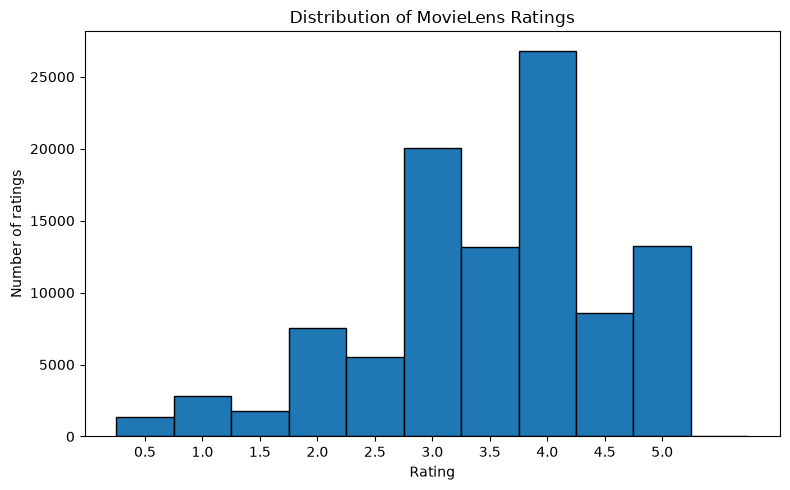

In [7]:
rating_levels = np.arange(0.5, 5.5, 0.5)
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(ratings["rating"], bins=np.arange(0.25, 5.76, 0.5), edgecolor="black")
ax.set_title("Distribution of MovieLens Ratings")
ax.set_xlabel("Rating")
ax.set_ylabel("Number of ratings")
ax.set_xticks(rating_levels)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_rating_histogram.png", dpi=150)
plt.show()

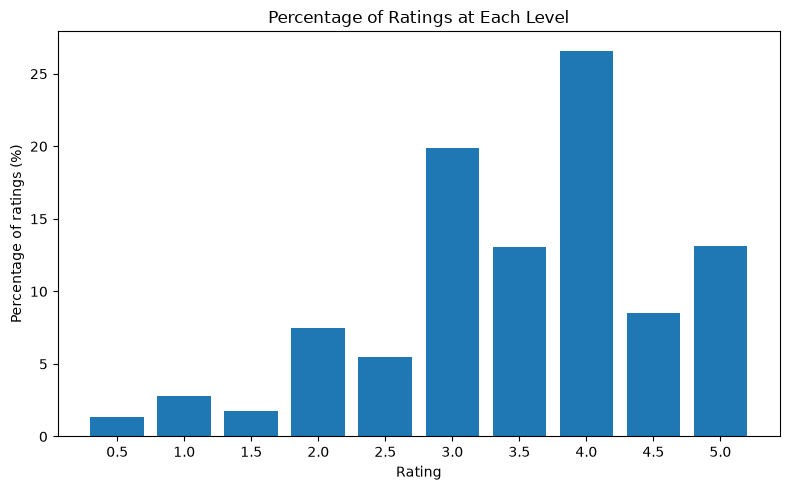

,percentage
rating,
0.5,1.36
1.0,2.79
1.5,1.78
2.0,7.49
2.5,5.50
3.0,19.88
3.5,13.03
4.0,26.60
4.5,8.48


In [8]:
rating_percentages = (
    ratings["rating"].value_counts(normalize=True).sort_index().mul(100)
)
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(rating_percentages.index.astype(str), rating_percentages.values)
ax.set_title("Percentage of Ratings at Each Level")
ax.set_xlabel("Rating")
ax.set_ylabel("Percentage of ratings (%)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "02_rating_level_percentages.png", dpi=150)
plt.show()

rating_percentages.round(2).rename("percentage").to_frame()

Ratings lean positive: 4.0 is the most common value (26.60%), and ratings of 4.0 or higher account for 48.18% of interactions. Low ratings are comparatively rare. If explicit ratings are converted to implicit feedback, treating every rating as equally positive would obscure dislike signals; a defensible threshold or confidence weighting will therefore be important.

## 4. User Activity Analysis

For descriptive identification, users with at most 25 ratings are labelled low-activity and users with at least 200 ratings are labelled heavy users. These thresholds describe this dataset only and do not filter any observations.

In [9]:
user_activity_statistics = ratings_per_user.describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
).to_frame("ratings_per_user")
low_activity_users = ratings_per_user[ratings_per_user <= 25]
heavy_users = ratings_per_user[ratings_per_user >= 200]

print(f"Low-activity users (≤25 ratings): {len(low_activity_users)}")
print(f"Heavy users (≥200 ratings): {len(heavy_users)}")
user_activity_statistics

Low-activity users (≤25 ratings): 72
Heavy users (≥200 ratings): 134


,ratings_per_user
count,610.000000
mean,165.304918
std,269.480584
min,20.000000
25%,35.000000
50%,70.500000
75%,168.000000
90%,400.300000
95%,610.750000
99%,1256.220000


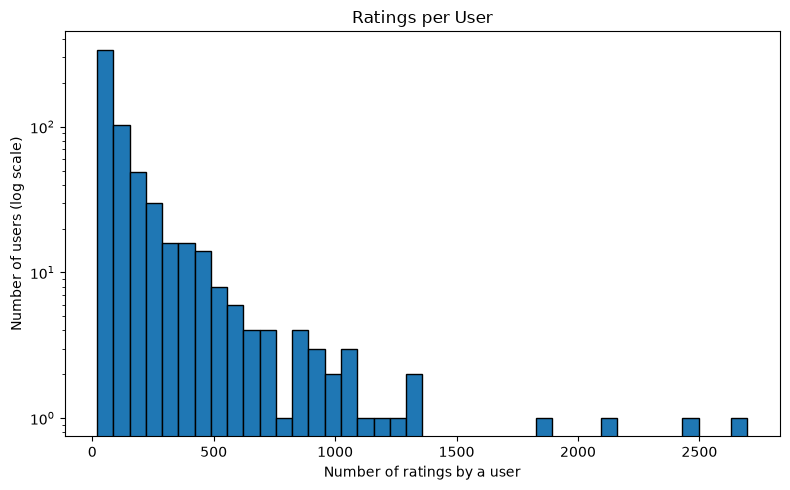

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(ratings_per_user, bins=40, edgecolor="black")
ax.set_yscale("log")
ax.set_title("Ratings per User")
ax.set_xlabel("Number of ratings by a user")
ax.set_ylabel("Number of users (log scale)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_user_activity_histogram.png", dpi=150)
plt.show()

User activity is strongly right-skewed: the median user has 70.5 ratings, while the maximum is 2,698. There are 72 low-activity users under the stated threshold and 134 heavy users. This long tail means highly active users contribute disproportionate training signal. The dataset's minimum is 20 ratings because of MovieLens inclusion rules, so it understates true new-user cold start; future evaluation should explicitly simulate users with shorter histories.

## 5. Movie Popularity Analysis

In [11]:
movie_popularity_statistics = ratings_per_movie.describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
).to_frame("ratings_per_movie")
movies_with_five_or_fewer_ratings = ratings_per_movie.le(5).sum()
print(f"Rated movies with five or fewer ratings: {movies_with_five_or_fewer_ratings}")
movie_popularity_statistics

Rated movies with five or fewer ratings: 6456


,ratings_per_movie
count,9724.000000
mean,10.369807
std,22.401005
min,1.000000
25%,1.000000
50%,3.000000
75%,9.000000
90%,27.000000
95%,47.000000
99%,114.540000


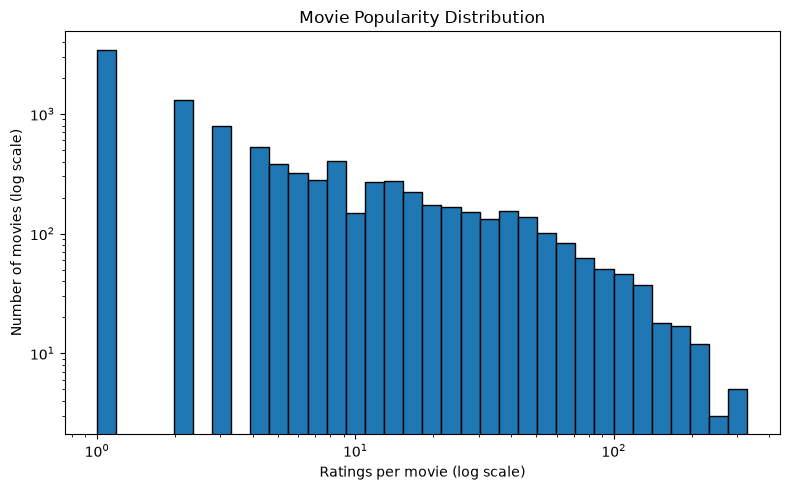

In [12]:
popularity_bins = np.logspace(0, np.log10(ratings_per_movie.max()), 35)
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(ratings_per_movie, bins=popularity_bins, edgecolor="black")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("Movie Popularity Distribution")
ax.set_xlabel("Ratings per movie (log scale)")
ax.set_ylabel("Number of movies (log scale)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_movie_popularity_histogram.png", dpi=150)
plt.show()

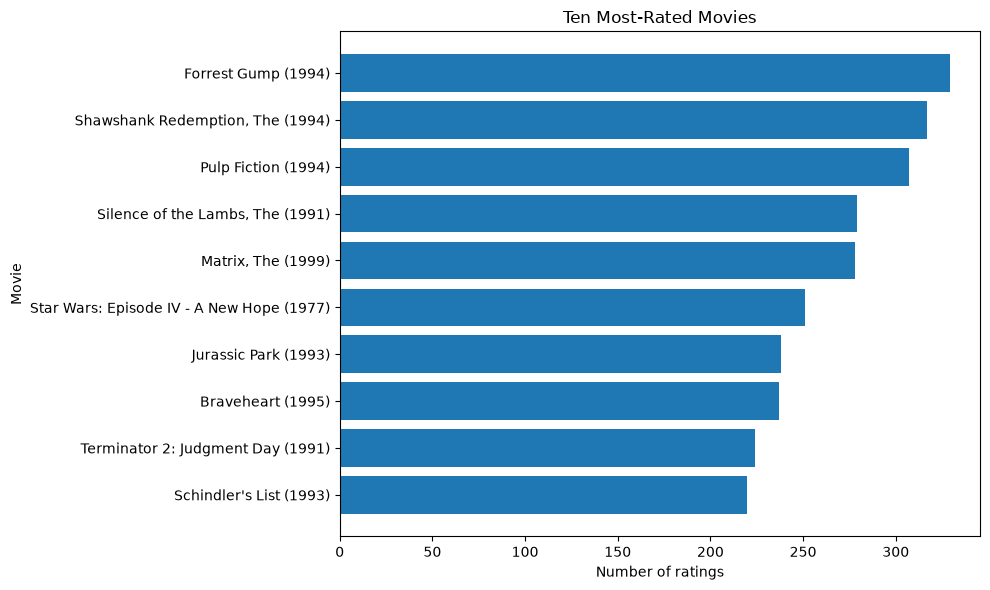

,rating_count,title
movieId,,
356,329,Forrest Gump (1994)
318,317,"Shawshank Redemption, The (1994)"
296,307,Pulp Fiction (1994)
593,279,"Silence of the Lambs, The (1991)"
2571,278,"Matrix, The (1999)"
260,251,Star Wars: Episode IV - A New Hope (1977)
480,238,Jurassic Park (1993)
110,237,Braveheart (1995)
589,224,Terminator 2: Judgment Day (1991)


In [13]:
movie_rating_counts = (
    ratings_per_movie.rename("rating_count")
    .to_frame()
    .join(movies.set_index("movieId")[["title"]])
    .sort_values("rating_count", ascending=False)
)
most_rated_movies = movie_rating_counts.head(10).sort_values("rating_count")
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(most_rated_movies["title"], most_rated_movies["rating_count"])
ax.set_title("Ten Most-Rated Movies")
ax.set_xlabel("Number of ratings")
ax.set_ylabel("Movie")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_most_rated_movies.png", dpi=150)
plt.show()

movie_rating_counts.head(10)

Movie popularity has a pronounced long tail: the median rated movie has only 3 ratings, 6,456 movies have at most 5, and the most-rated movie has 329. A model optimized only for aggregate accuracy may repeatedly recommend blockbusters because they offer abundant signal, creating popularity bias and weak exposure for niche items.

## 6. Genre Analysis

In [14]:
genre_counts = movies["genres"].str.split("|").explode().value_counts()
genre_count_per_movie = movies["genres"].str.count(r"\|") + 1
multi_genre_movies = genre_count_per_movie.gt(1).sum()

print(f"Multi-genre movies: {multi_genre_movies:,} ({multi_genre_movies / len(movies):.2%})")
genre_counts.to_frame("movie_count")

Multi-genre movies: 6,891 (70.73%)


,movie_count
genres,
Drama,4361
Comedy,3756
Thriller,1894
Action,1828
Romance,1596
Adventure,1263
Crime,1199
Sci-Fi,980
Horror,978


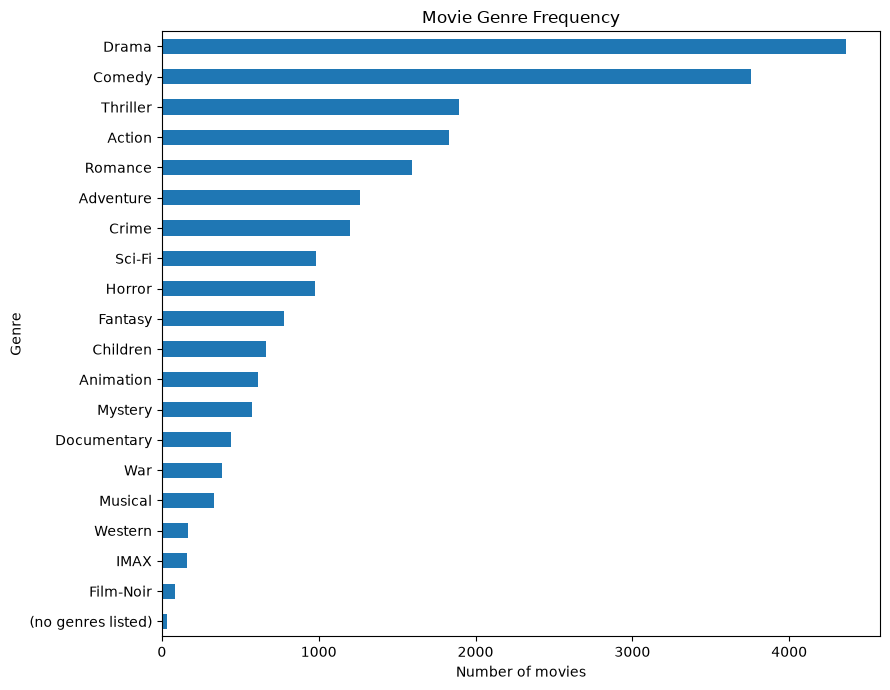

In [15]:
fig, ax = plt.subplots(figsize=(9, 7))
genre_counts.sort_values().plot.barh(ax=ax)
ax.set_title("Movie Genre Frequency")
ax.set_xlabel("Number of movies")
ax.set_ylabel("Genre")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "06_genre_distribution.png", dpi=150)
plt.show()

Drama and Comedy dominate the catalog, and 6,891 movies (70.73%) have multiple genre labels. Genre indicators could later support content-aware recommendation, especially for sparse or new items, but multi-label representation and broad genre imbalance would need careful treatment.

## 7. Temporal Analysis

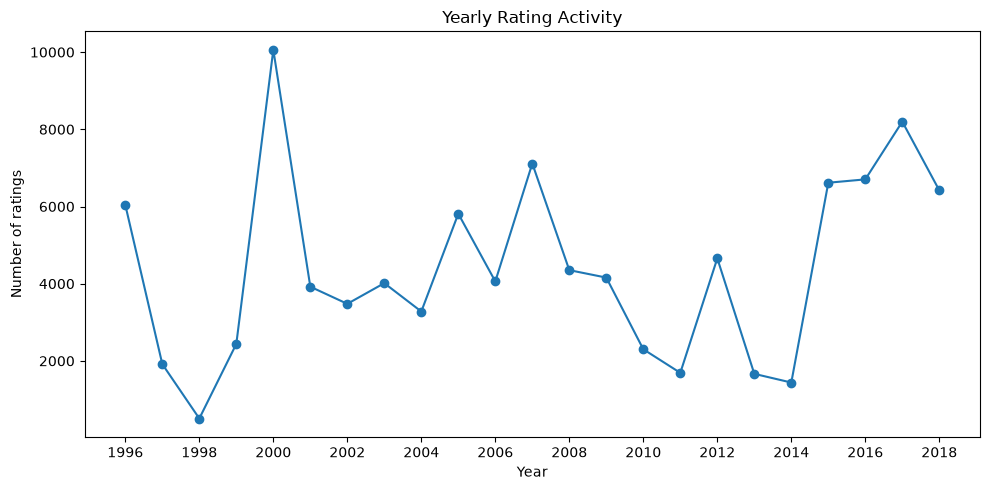

,rating_count
rating_datetime,
1996,6040
1997,1916
1998,507
1999,2439
2000,10061
2001,3922
2002,3478
2003,4014
2004,3279


In [16]:
ratings_with_time = ratings.assign(
    rating_datetime=pd.to_datetime(ratings["timestamp"], unit="s")
)
yearly_activity = ratings_with_time.groupby(
    ratings_with_time["rating_datetime"].dt.year
).size()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(yearly_activity.index, yearly_activity.values, marker="o")
ax.set_title("Yearly Rating Activity")
ax.set_xlabel("Year")
ax.set_ylabel("Number of ratings")
ax.set_xticks(yearly_activity.index[::2])
fig.tight_layout()
fig.savefig(FIGURES_DIR / "07_yearly_rating_activity.png", dpi=150)
plt.show()

yearly_activity.rename("rating_count").to_frame()

Activity is uneven over the 1996–2018 span, with pronounced peaks around 2000 and 2015–2018. Random splitting could leak later behaviour into training and conceal preference drift. Temporal ordering may therefore improve realistic evaluation and could support time-aware weighting or recency-sensitive recommendation in later stages.

## 8. Sparsity Analysis

The interaction matrix is constructed in memory only and is not saved as a processed dataset.

In [17]:
interaction_matrix = ratings.pivot(
    index="userId", columns="movieId", values="rating"
)
possible_interactions = interaction_matrix.size
observed_interactions = int(interaction_matrix.notna().sum().sum())
sparsity_percentage = 100 * (1 - observed_interactions / possible_interactions)

pd.Series(
    {
        "Matrix rows (users)": interaction_matrix.shape[0],
        "Matrix columns (rated movies)": interaction_matrix.shape[1],
        "Possible interactions": possible_interactions,
        "Observed interactions": observed_interactions,
        "Sparsity (%)": sparsity_percentage,
    },
    name="Value",
)

Matrix rows (users)              6.100000e+02
Matrix columns (rated movies)    9.724000e+03
Possible interactions            5.931640e+06
Observed interactions            1.008360e+05
Sparsity (%)                     9.830003e+01
Name: Value, dtype: float64

Only 100,836 of 5,931,640 possible user–movie interactions are observed, producing 98.30% sparsity. This is central to recommendation because most user preferences are unknown: collaborative methods must infer rankings from limited overlap, and evidence is especially weak for low-activity users and long-tail movies.

## 9. Research Observations

MovieLens Latest Small is a compact explicit-feedback dataset with 610 users, 9,742 catalog movies, and 100,836 ratings spanning more than 22 years. Ratings lean positive, user activity is highly unequal, and item exposure follows a strong long-tail pattern. The interaction matrix is 98.30% sparse despite the dataset requiring each included user to have at least 20 ratings.

The principal modelling challenges are sparse preference evidence, popularity bias, limited evidence for niche items, and an evaluation population that understates genuine new-user cold start. Uneven activity over time also creates a risk that random evaluation splits will overestimate performance by ignoring chronology and preference drift. Positive-rating dominance requires care if explicit scores are transformed into binary interactions.

Future modelling can exploit several opportunities without changing the present raw data. Ranking objectives and Top-K metrics can align evaluation with the recommendation task; popularity-aware baselines can reveal whether personalization adds value; genre metadata can support content-aware signals for sparse items; and time-respecting evaluation can test generalization to future interactions. Coverage, novelty, and popularity-stratified results should complement accuracy metrics so improvements do not merely concentrate recommendations on already popular movies.